# MicroProyecto # 1 de Tecnicas de Deep Learning — MAIA

**Nombre de los estudiantes:**  Jairo Alexander López Garcia -  Miguel Angel Rodriguez Marin - Jaime Andres Usme Cerquera

**Código:**  `202615506`  -  `XXXXXXXXXX`  - `XXXXXXXXXXX`

**Maestría:** Maestría en Inteligencia Artificial (MAIA)

**Fecha:**  03/11/2026

### 1. Realizamos la importación de las librerias necesarias para la ejecución del notebook

In [1]:
import torch                     # Importar PyTorch
import torch.nn as nn            # Módulo de redes neuronales de PyTorch
import torch.optim as optim      # Optimizadores de PyTorch
import numpy as np               # Librería para trabajar con datos matriciales
import matplotlib.pyplot as plt  # Librería para gráficas y visualización
import os
import hashlib, collections

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split


### 2. Se fijan las semillas de los generadores de números aleatorios

In [2]:
# Inicialización de semillas
torch.manual_seed(42)
np.random.seed(42)

# Dispositivo de cómputo (usa GPU si está disponible)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

### 3. Validamos que los ruta de los datos se encuentre correcta y con sus correspondientes subcarpetas.

In [3]:
path = 'data'
print(path, os.listdir(path)) 

data ['glioma', 'healthy', 'meningioma', 'pituitary']


### 4. Validación de duplicados
Se realiza una validación de imagenes duplicadas, esta validación se realiza por medio del hash MD5 del archivo.
Como se encuentran duplicados en las imagenes se validaran dentro del codigo de la función Load_ data().

In [4]:
samples = datasets.ImageFolder("data").samples
hash_to_files = collections.defaultdict(list)
for ruta, etiqueta in samples:
    with open(ruta, "rb") as f:
        hash_to_files[hashlib.md5(f.read()).hexdigest()].append((ruta, etiqueta))

grupos_dup = [v for v in hash_to_files.values() if len(v) > 1]
n_dup = sum(len(v) - 1 for v in grupos_dup)
print(f"Total imágenes: {len(samples)}")
print(f"Imágenes únicas: {len(hash_to_files)}")
print(f"Duplicados: {n_dup}")

# Duplicados con la misma imagen en dos clases
conflictos = [v for v in grupos_dup if len({e for _, e in v}) > 1]
print(f"Duplicados en clases distintas: {len(conflictos)}")

Total imágenes: 7023
Imágenes únicas: 6597
Duplicados: 426
Duplicados en clases distintas: 0


### 5. Se crea una función para la preparación y carga de los datos..
La función realiza lo siguiente: Normaliza las imagenes, carga las imagenes, elimina las imagenes duplicadas, se cargan en un unico tensor 

In [5]:
def load_data(dataset_cls=datasets.ImageFolder, data_dir="./data",
              img_size=128, test_size=0.2, seed=42):
    """
    Esta función carga al entorno de trabajo los datos de entrenamiento y prueba del
    conjunto Brain Tumor MRI Scans como tensores de PyTorch.
    Parámetros de entrada:
    dataset_cls = Clase de torchvision.datasets para leer imágenes organizadas en
                  carpetas por clase (ImageFolder)
    data_dir = Carpeta donde están almacenados los datos (una subcarpeta por clase)
    img_size = Tamaño (alto y ancho) al que se redimensionan las imágenes
    test_size = Proporción de los datos que se reserva para prueba
    seed = Semilla para que la división train/test sea reproducible
    Parámetros de salida:
    X_train = Conjunto de datos para entrenamiento, tensor de forma (N_train, 1, img_size, img_size)
    X_test = Conjunto de datos para prueba, tensor de forma (N_test, 1, img_size, img_size)
    y_train = Etiqueta del conjunto de entrenamiento (índices de clase 0-3)
    y_test = Etiqueta del conjunto de prueba (índices de clase 0-3)
    classes = Nombres de las clases en el orden de sus índices
    """

    # Las imágenes vienen en tamaños distintos y algunas en RGB: se pasan a escala de grises y a un tamaño fijo. ToTensor ya normaliza los píxeles a [0, 1].
    transform = transforms.Compose([
        transforms.Grayscale(num_output_channels=1),
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
    ])

    # Carga de las imágenes (la etiqueta es el nombre de la carpeta)
    dataset = dataset_cls(root=data_dir, transform=transform)

    # Eliminar imágenes duplicadas (se conserva la primera)
    vistos, unicos = set(), []
    for ruta, etiqueta in dataset.samples:
        with open(ruta, "rb") as f:
            h = hashlib.md5(f.read()).hexdigest()
        if h not in vistos:
            vistos.add(h)
            unicos.append((ruta, etiqueta))
    print(f'Duplicados eliminados: {len(dataset.samples) - len(unicos)}')
    dataset.samples = dataset.imgs = unicos
    dataset.targets = [e for _, e in unicos]

    # Se leen todas las imágenes y se cargan en un único tensor
    loader = DataLoader(dataset, batch_size=256, shuffle=False)
    X_list, y_list = [], []
    for imgs, labels in loader:
        X_list.append(imgs)
        y_list.append(labels)
    X = torch.cat(X_list)   # (N, 1, img_size, img_size)
    y = torch.cat(y_list)   # (N,)

    # División estratificada: mantiene la misma proporción de clases en train y test
    idx_train, idx_test = train_test_split(
        np.arange(len(y)), test_size=test_size,
        stratify=y.numpy(), random_state=seed
    )
    X_train, X_test = X[idx_train], X[idx_test]
    y_train, y_test = y[idx_train], y[idx_test]

    print(f'Conjunto de datos cargados')
    print(f'Clases {dataset.class_to_idx}')
    print(f'Tamaño imágenes de entrenamiento {tuple(X_train.shape)}')
    print(f'Tamaño imágenes de test {tuple(X_test.shape)}')
    print(f'Datos por cada etiqueta en X train {np.bincount(y_train.numpy())}')

    # Los tensores ya incluyen la dimensión del canal (N, C, H, W)
    return X_train, X_test, y_train, y_test, dataset.classes

### 6. Se ejecuta el pipeline de preparación de datos.

In [6]:
X_train, X_test, y_train, y_test, classes = load_data(datasets.ImageFolder, "./data")

Duplicados eliminados: 426
Conjunto de datos cargados
Clases {'glioma': 0, 'healthy': 1, 'meningioma': 2, 'pituitary': 3}
Tamaño imágenes de entrenamiento (5277, 1, 128, 128)
Tamaño imágenes de test (1320, 1, 128, 128)
Datos por cada etiqueta en X train [1296 1364 1225 1392]


### 7. Realizamos la división del entrenamiento en entrenamiento (85%) y validación (15%), cada grupo queda con la misma mezcla de tipos de tumor.

In [7]:
idx_tr, idx_val = train_test_split(np.arange(len(y_train)), test_size=0.15, stratify=y_train.numpy(), random_state=42)
X_val, y_val = X_train[idx_val], y_train[idx_val]
X_train, y_train = X_train[idx_tr], y_train[idx_tr]

print(f'Train: {tuple(X_train.shape)}  Val: {tuple(X_val.shape)}  Test: {tuple(X_test.shape)}')
print(f'Distribución val: {np.bincount(y_val.numpy())}  test: {np.bincount(y_test.numpy())}')

Train: (4485, 1, 128, 128)  Val: (792, 1, 128, 128)  Test: (1320, 1, 128, 128)
Distribución val: [194 205 184 209]  test: [324 342 306 348]


### 8. Realizamos el gráfico de distribución de clases en entrenamiento, validación y prueba

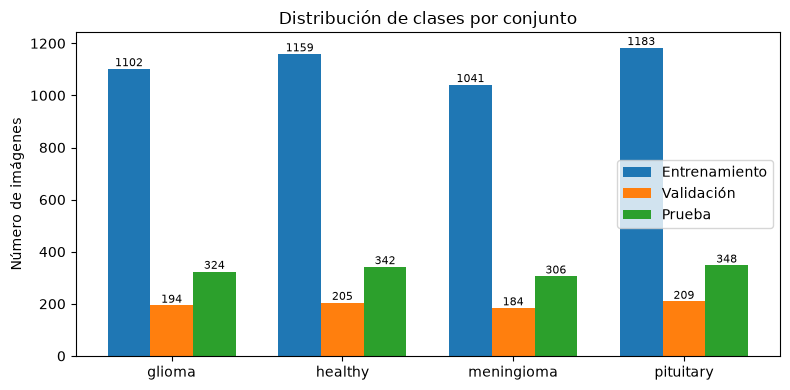

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(classes))
ancho = 0.25
for i, (nombre, y) in enumerate([("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]):
    conteos = np.bincount(y.numpy(), minlength=len(classes))
    barras = ax.bar(x + (i - 1) * ancho, conteos, ancho, label=nombre)
    ax.bar_label(barras, fontsize=8)   # número encima de cada barra
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylabel("Número de imágenes")
ax.set_title("Distribución de clases por conjunto")
ax.legend()
plt.tight_layout()
plt.show()

### 9. Mostramos las primeras 8 imágenes de entrenamiento con el nombre de su clase, para validar que tienen la etiqueta correcta.

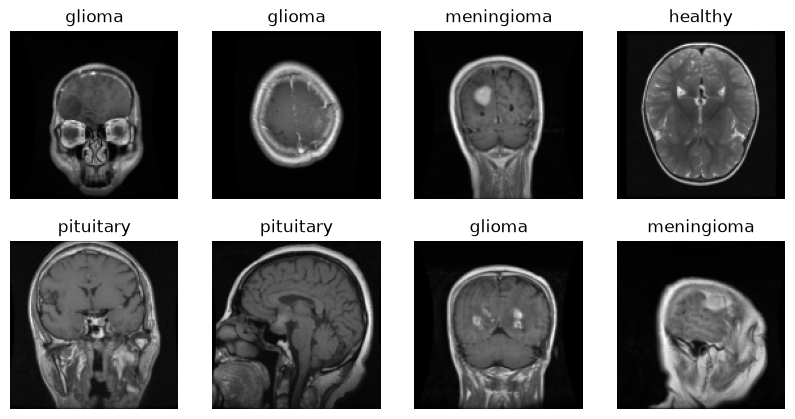

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, img, lbl in zip(axes.flat, X_train[:8], y_train[:8]):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(classes[lbl])
    ax.axis("off")
plt.show()

## 10. Arquitectura de la red neuronal convolucional

Se diseñó una red convolucional propia para clasificar cada resonancia magnética en una de
las 4 categorías: glioma, healthy, meningioma o pituitary.

La red recibe una imagen en escala de grises de 128 × 128 píxeles y la procesa con tres capas
de convolución. Cada una aprende a detectar patrones en la imagen: primero bordes y contrastes,
luego texturas y formas, y finalmente estructuras más complejas. Entre las capas de convolución se usan capas de max pooling, que reducen el tamaño de la imagen a la mitad conservando la información más importante. Esto hace la red más rápida y
tolerante a pequeños cambios de posición.

Al final, una capa de salida toma todo lo aprendido y asigna un puntaje a cada una de las
4 clases; la clase con el puntaje más alto es la predicción del modelo.

In [10]:
def load_model():
    """
    Esta función construye un modelo neuronal convolucional para el problema de clasificación con Brain Tumor MRI.
    Salida: model = modelo neuronal convolucional en PyTorch (nn.Module)
    """
    model = nn.Sequential(
        # Primera capa convolucional. Kernel de 3x3 y 16 filtros
        nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
        nn.ReLU(),
        # Capa de MaxPooling
        nn.MaxPool2d(kernel_size=2),
        
        # Segunda capa convolucional. Kernel de 3x3 y 32 filtros
        nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
        nn.ReLU(),
        # Capa de MaxPooling
        nn.MaxPool2d(kernel_size=2),
        
         # Tercera capa convolucional. Kernel de 3x3 y 32 filtros
        nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
        nn.ReLU(),

    
        # Capa de aplanamiento
        nn.Flatten(),
        # Capa de salida
        nn.Linear(32 * 32 * 32, 4)
    )

    return model

### 11. Resumen del modelo

Se construye la red y se muestra su estructura: la lista de capas en el orden en que procesan
la imagen. También se calcula el número de parámetros entrenables, que son los valores internos
que el modelo ajusta durante el aprendizaje. Este número da una idea del tamaño de la red: entre
más parámetros, más capacidad tiene para aprender, pero también más riesgo de memorizar los
datos en lugar de generalizar.

In [11]:
model = load_model()
print(model)
print(f"Parámetros entrenables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=32768, out_features=4, bias=True)
)
Parámetros entrenables: 145,124


### 12. Transformaciones aleatorias solo para entrenamiento (data augmentation)
Se realizan transformaciones aleatorias a las imagenes ya que en las primeras pruebas el modelo estaba quedando sobreajustado (accuracy cerca al 99% en entrenamiento y en test por debajo del 90%, la perdida en test aumentaba despues de la quinta epoca) con esto realizamos modificaciones de posición y rotación para que el modelo no siempre entrene con la misma imagen dos veces.

In [12]:
augment = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
])

### 13. Creamos la funcion que mide qué tan bien clasifica el modelo un grupo de imágenes.

In [13]:
def evaluate_model(model, X, y, batch_size=128, criterion=None):
    """
    Evalúa `model` sobre (X, y) y calcula la pérdida y precisión promedio,
    de forma equivalente a model.evaluate() en tensorflow.keras.
    Parámetros de entrada:
    model = modelo de PyTorch (nn.Module)
    X, y = datos y etiquetas sobre los que evaluar
    batch_size = tamaño de lote usado para recorrer los datos
    criterion = función de pérdida (por defecto nn.CrossEntropyLoss)
    Salida:
    loss = pérdida promedio
    accuracy = precisión promedio
    """
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            X_batch = X[i:i + batch_size].to(device)
            y_batch = y[i:i + batch_size].to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            total_loss += loss.item() * len(X_batch)
            correct += (outputs.argmax(dim=1) == y_batch).sum().item()
            total += len(X_batch)

    return total_loss / total, correct / total


### 14. Creamos la funcion que realiza el entrenamiento del modelo

In [14]:
def train_model(model, X_train, y_train, X_test, y_test, optimizer,
                 epochs=10, batch_size=32, criterion=None):
    """
    Entrena `model` durante `epochs` épocas usando mini-lotes de tamaño `batch_size`,
    evaluando en cada época sobre (X_test, y_test), de forma equivalente a
    model.fit(..., validation_data=(X_test, y_test)) en tensorflow.keras.
    Parámetros de entrada:
    model = modelo de PyTorch (nn.Module)
    X_train, y_train = datos y etiquetas de entrenamiento
    X_test, y_test = datos y etiquetas de validación/prueba
    optimizer = optimizador de torch.optim ya asociado a los parámetros de `model`
    epochs = número de épocas de entrenamiento
    batch_size = tamaño de mini-lote
    criterion = función de pérdida (por defecto nn.CrossEntropyLoss)
    Salida:
    history = diccionario con las llaves 'accuracy', 'val_accuracy', 'loss', 'val_loss'
    """
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model.to(device)
    n_train = len(X_train)
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n_train)
        running_loss, correct, total = 0.0, 0, 0

        for i in range(0, n_train, batch_size):
            idx = perm[i:i + batch_size]
            X_batch = X_train[idx].to(device)
            y_batch = y_train[idx].to(device)

            # Data augmentation: cada imagen del lote recibe una transformación aleatoria
            X_batch = torch.stack([augment(img) for img in X_batch])

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(X_batch)
            correct += (outputs.argmax(dim=1) == y_batch).sum().item()
            total += len(X_batch)

        train_loss, train_acc = running_loss / total, correct / total
        val_loss, val_acc = evaluate_model(model, X_test, y_test, batch_size=batch_size, criterion=criterion)

        history['accuracy'].append(train_acc)
        history['val_accuracy'].append(val_acc)
        history['loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        print(f"Epoch {epoch + 1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

    return history

In [15]:
# Compilar y entrenar el modelo
model = load_model()
optimizer = optim.Adam(model.parameters(), lr=0.001)
resultsFit = train_model(model, X_train, y_train, X_val, y_val,
                          optimizer=optimizer,
                          epochs=30,
                          batch_size=32)

Epoch 1/30 - loss: 0.8421 - accuracy: 0.6635 - val_loss: 0.6967 - val_accuracy: 0.7197
Epoch 2/30 - loss: 0.6316 - accuracy: 0.7572 - val_loss: 0.5233 - val_accuracy: 0.7980
Epoch 3/30 - loss: 0.5205 - accuracy: 0.8002 - val_loss: 0.4532 - val_accuracy: 0.8359
Epoch 4/30 - loss: 0.4834 - accuracy: 0.8123 - val_loss: 0.3721 - val_accuracy: 0.8662
Epoch 5/30 - loss: 0.4429 - accuracy: 0.8381 - val_loss: 0.3742 - val_accuracy: 0.8737
Epoch 6/30 - loss: 0.4291 - accuracy: 0.8386 - val_loss: 0.3585 - val_accuracy: 0.8586
Epoch 7/30 - loss: 0.3968 - accuracy: 0.8499 - val_loss: 0.3130 - val_accuracy: 0.9040
Epoch 8/30 - loss: 0.3789 - accuracy: 0.8555 - val_loss: 0.3135 - val_accuracy: 0.8965
Epoch 9/30 - loss: 0.3482 - accuracy: 0.8647 - val_loss: 0.3298 - val_accuracy: 0.8851
Epoch 10/30 - loss: 0.3457 - accuracy: 0.8720 - val_loss: 0.2964 - val_accuracy: 0.8876
Epoch 11/30 - loss: 0.3452 - accuracy: 0.8696 - val_loss: 0.3199 - val_accuracy: 0.8725
Epoch 12/30 - loss: 0.3218 - accuracy: 0.

In [16]:
def visualization_history(resultsFit):
    """
    Esta función grafica las curvas de precisión a lo largo de las épocas de entrenamiento
    para el conjunto de prueba como el de validación.
    Parámetros:
    resultsFit = historial de entrenamiento (diccionario con las llaves 'accuracy',
    'val_accuracy', 'loss', 'val_loss')
    Salida:
    Gráfica de la precisión en validación y prueba.
    """
    # Llamado al entrono de la gráfica y fijar tamaño de visualización
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Graficar la presición de la historia en entrenamiento
    axes[0].plot(range(len(resultsFit['accuracy'])), resultsFit['accuracy'],
           '#5a2ff4', linestyle = "-", marker = "o",
           label='Precisión entrenamiento', lw = 3)

    # Graficar la presición de la historia en validación
    axes[0].plot(range(len(resultsFit['val_accuracy'])), resultsFit['val_accuracy'],  '#60d13e',
           label='Precisión validación', linestyle = '-', marker = 'o', lw = 3)

    # Umbral 90% de precisión
    axes[0].plot(range(len(resultsFit['val_accuracy'])), 0.9*np.ones(len(resultsFit['val_accuracy'])),
               'red', lw = 3, label = 'Umbral')

    # Títulos de los ejes
    axes[0].set_xlabel('Época',fontsize=16)
    axes[0].set_ylabel(r'Precisión',fontsize=16)
    axes[0].set_ylim(top=1) # Límite de la grafica
    axes[0].grid()      # Activar la cuadricula
    axes[0].legend(fontsize=14,loc = 'lower right')   # Establecer la legenda


    # Graficar la pérdida de la historia en entrenamiento
    axes[1].plot(range(len(resultsFit['loss'])), resultsFit['loss'],
           '#5a2ff4', linestyle = "-", marker = "o",
           label='Pérdida entrenamiento', lw = 3)

    # Graficar la presición de la historia en validación
    axes[1].plot(range(len(resultsFit['val_loss'])), resultsFit['val_loss'],  '#60d13e',
           label='Pérdida validación', linestyle = '-', marker = 'o', lw = 3)

    # Títulos de los ejes
    axes[1].set_xlabel('Época',fontsize=16)
    axes[1].set_ylabel(r'Pérdida',fontsize=16)
    axes[1].grid()      # Activar la cuadricula
    axes[1].legend(fontsize=14,loc = 'upper right')   # Establecer la legenda


    plt.tight_layout() # Ajusta automáticamente el diseño de la figura
    plt.show()
### END READ ONLY

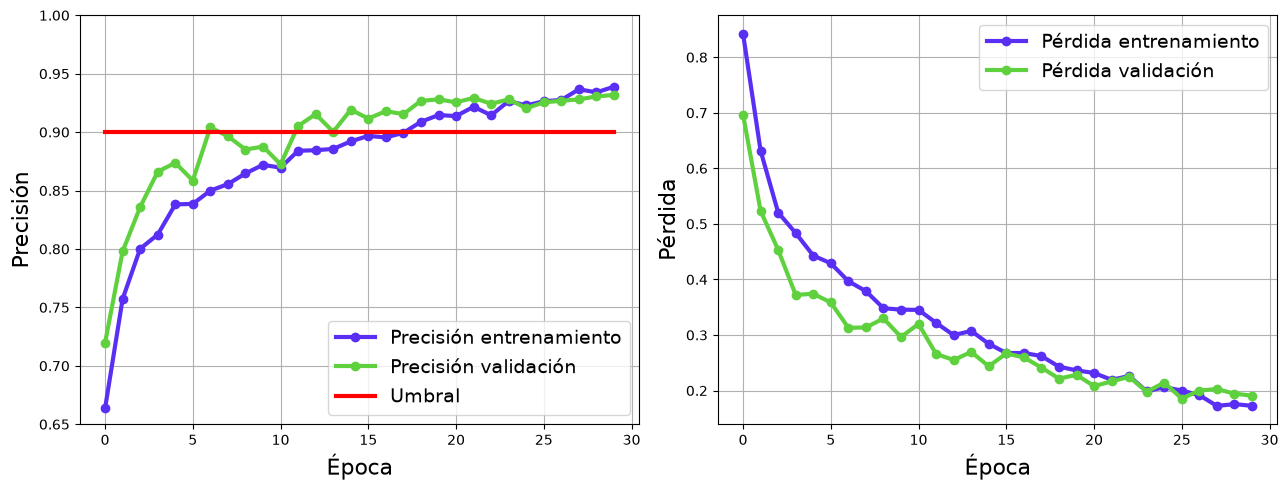

In [17]:
# Llamado a la función de visualización de las métricas de la historia del entrenamiento
# del modelo, en la prrimera gráfica se presenta la precisión y en la segunda la pérdida
visualization_history(resultsFit)

In [18]:
test_loss, test_acc = evaluate_model(model, X_test, y_test)
print(f'Prueba final - loss: {test_loss:.4f} - accuracy: {test_acc:.4f}')

Prueba final - loss: 0.1995 - accuracy: 0.9402
